In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn import metrics
from sklearn.metrics import mean_absolute_percentage_error

### Se pide, usando regresión lineal:

Dibujar con una línea la relación que hay entre la altura y la edad de los alumnos de esta clase: 

In [4]:
lista_alumnos = [("Leonardo S", 24, 1.82), 
                 ("Piero T", 25, 1.71), 
                 ("Marta B", 35, 1.66), 
                 ("Silvia P", 37, 1.63), 
                 ("Faro Z", 29, 1.90), 
                 ("Miguel N", 27, 1.80), 
                 ("Alejandro M", 28, 1.70), 
                 ("Cristina M", 32, 1.60), 
                 ("Francisco P", 36, 1.74), 
                 ("Jorge D", 45, 1.72), 
                 ("Jesús L", 41, 1.65), 
                 ("Marta G", 30, 1.65), 
                 ("Jennifer S", 40, 1.60), 
                 ("Diego I", 39, 1.80), 
                 ("Antonio C", 23, 1.77), 
                 ("Juan M", 32, 1.75), 
                 ("David S", 27, 1.70), 
                 ("Antonio J", 34, 1.80), 
                 ("Carlos H", 27, 1.77), 
                 ("Erik U", 28, 1.70), 
                 ("Marcos L", 35, 1.80)] 

### ¿Es una buena técnica para este tipo de problemas? Demuéstralo antes de entrenar un modelo con un análisis descriptivo.

In [5]:
alumnos=pd.DataFrame(lista_alumnos).rename(columns={0:"Nombre", 1:"Edad", 2:"Altura"})
alumnos

,Nombre,Edad,Altura
0,Leonardo S,24,1.82
1,Piero T,25,1.71
2,Marta B,35,1.66
3,Silvia P,37,1.63
4,Faro Z,29,1.90
5,Miguel N,27,1.80
6,Alejandro M,28,1.70
7,Cristina M,32,1.60
8,Francisco P,36,1.74
9,Jorge D,45,1.72


In [6]:
alumnos.info()

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Nombre  21 non-null     str    
 1   Edad    21 non-null     int64  
 2   Altura  21 non-null     float64
dtypes: float64(1), int64(1), str(1)
memory usage: 806.0 bytes


In [7]:
alumnos.describe()

,Edad,Altura
count,21.000000,21.000000
mean,32.095238,1.727143
std,6.081980,0.079003
min,23.000000,1.600000
25%,27.000000,1.660000
50%,32.000000,1.720000
75%,36.000000,1.800000
max,45.000000,1.900000


<Axes: xlabel='Edad', ylabel='Altura'>

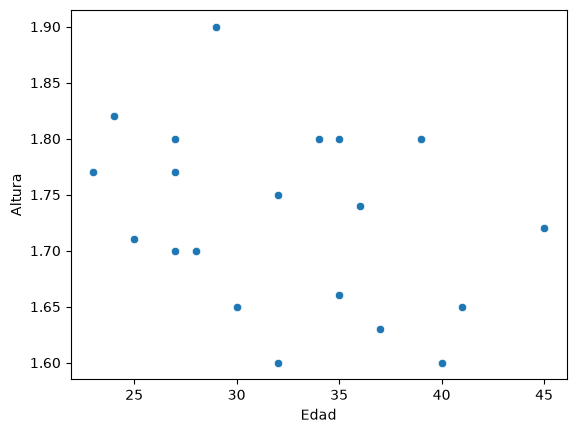

In [8]:
sns.scatterplot(data=alumnos,x="Edad",y="Altura")

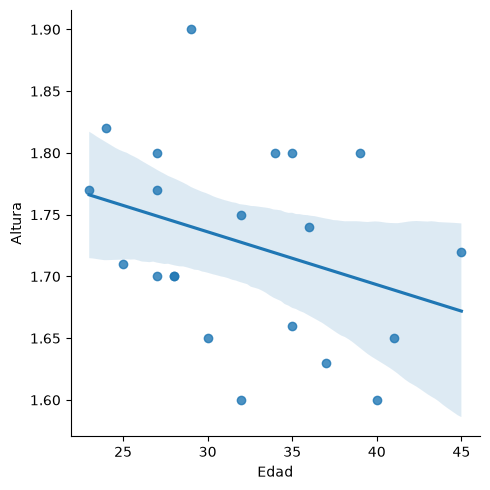

In [9]:
sns.lmplot(data=alumnos,x="Edad",y="Altura")

<Axes: >

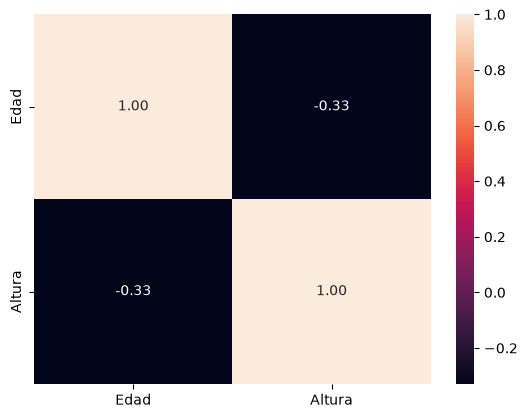

In [10]:
sns.heatmap(data=alumnos[["Edad","Altura"]].corr(),annot=True,fmt=".2f")

<Axes: xlabel='Altura', ylabel='count'>

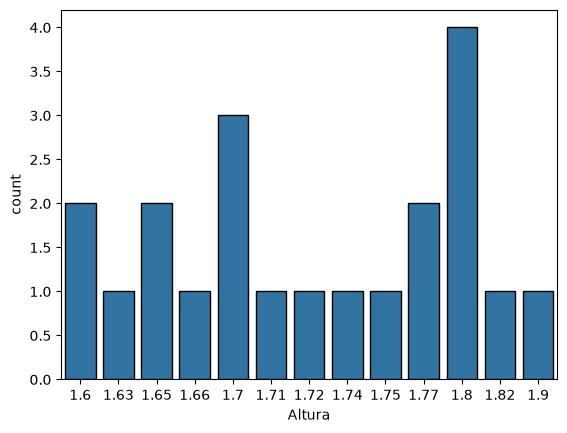

In [11]:
sns.countplot(data=alumnos,x="Altura",edgecolor="black")

### Entrena un modelo de regresión lineal

In [ ]:
X=alumnos[["Edad"]] # variables que utilizamos para hacer la predicción: es un df (doble corchete), ya que LinearRegression espera
                    #   recibir por 'X' una estructura de 2 dimensiones y por 'y' una de 1 dimensión
y=alumnos["Altura"] # lo que queremos predecir

# Dividir los datos en entrenamiento y prueba:
#   train -> datos que utilizaremos para enseñar al modelo
#   test -> datos que reservamos para comprobar si el modelo predice correctamente (5 filas)
#       test_size -> reservamos 5 datos para el test
#       random_state -> semilla, para que siempre salgan los mismos resultados con esos datos
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=5, random_state=42)

print("Dimensiones de los conjuntos:")
print(f"X_train: {X_train.shape}")
print(f"X_test:  {X_test.shape}")
print(f"y_train: {y_train.shape}")
print(f"y_test:  {y_test.shape}\n")

Dimensiones de los conjuntos:
X_train: (16, 1)
X_test:  (5, 1)
y_train: (16,)
y_test:  (5,)

Ecuación final: Altura = 1.86 + (-0.004 * Edad)


In [ ]:
# Crear un objeto LinearRegression: algoritmo que aprenderá la relación entre la edad y la altura más tarde
# La regresión lineal busca encontrar una recta que represente lo mejor posible la relación entre ambas variables.
# Fórmula de la regresión lineal -> y = a + bx
#   y: altura que queremos predecir
#   x: edad del alumno
#   a: intercepto (dónde corta la recta el eje Y), valor de la altura estimada cuando la edad es 0.
#   b: pendiente o coeficiente de la recta (cuánto cambia la altura por cada unidad que aumenta la edad)
model=LinearRegression()

# Entrenamos el modelo usando los datos de entrenamiento (train)
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[-0.]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['Edad']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,1.858
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [ ]:
# Valor de la altura estimada cuando la edad es 0.
a=model.intercept_ 

# Coeficiente o pendiente de la recta. Indica cuánto cambia la altura estimada cuando la edad aumenta una unidad (en este caso, un año).
# Usamos [0] porque model.coef_ devuelve un array con los coeficientes de las variables predictoras. Como solamente tenemos
#   una variable (Edad), solo tenemos un coeficiente.
b=model.coef_[0]

print(f"Ecuación final: Altura = {a:.2f} + ({b:.3f} * Edad)")
print(a+b*alumnos["Edad"])

Ecuación final: Altura = 1.86 + (-0.004 * Edad)
0     1.753478
1     1.749121
2     1.705549
3     1.696835
4     1.731692
5     1.740407
6     1.736049
7     1.718621
8     1.701192
9     1.661977
10    1.679406
11    1.727335
12    1.683763
13    1.688120
14    1.757835
15    1.718621
16    1.740407
17    1.709906
18    1.740407
19    1.736049
20    1.705549
Name: Edad, dtype: float64


y = a + b*x

altura = a + b*Edad

Altura = 1.86 - 0.004 * Edad

### ¿Qué error se comete? Calcula los errores que está cometiendo tu modelo de forma manual con python. Aparte, usa las métricas de sklearn MAE, MAPE, MSE y el RMSE.

In [ ]:
# En predictions guardamos ahora las alturas que el modelo predice para las edades de X_test
# Luego usamos y_test en los cáculos para comparar las alturas predichas con las alturas reales de y_test
predictions = model.predict(X_test)
print('MAE:', metrics.mean_absolute_error(y_test, predictions))
print('MAPE:', mean_absolute_percentage_error(y_test, predictions)*100)
print('MSE:', metrics.mean_squared_error(y_test, predictions))
print('RMSE:', np.sqrt(metrics.mean_squared_error(y_test, predictions)))

MAE: 0.05318486080700664
MAPE: 2.9943007687355165
MSE: 0.0033126493607306537
RMSE: 0.057555619714591326
